In [1]:
from anemone.forwards import ForwardMPA


In [2]:
from anemone.experiment import Loop, Receiver

In [3]:
import torch

In [5]:
t = torch.logspace(-5, -3, 31)
tx = Loop.square(40)
rx = Receiver()
fwr = ForwardMPA(tx, rx, t)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:108: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [7]:
rho = torch.tensor([40, 40, 40])
phi = 1/torch.tensor([0, 120, 240])
tau = torch.tensor([0.1, 0.2, 0.3])
c   = torch.tensor([0.1, 0.2, 0.3])
thk = torch.tensor([20,40])
dbdt = fwr(rho, phi, tau, c, thk)


NotImplementedError: 

In [163]:
from anemone.physics import colecole
import numpy as np
import matplotlib.pyplot as plt


def mpa2cc(rho, phi_max, tau_phi, C):
    n = 0
    m0 = 0.
    m_new = 1.
    
    tan_phi = np.tan(-phi_max)


    while np.abs(m_new-m0)/m_new > 1e-3 and n < 10:
        if n>0: m0 = m_new*1.
        tau_cc = tau_phi*(1.-m0)**(-0.5/C)
        ab = 1./(1.+(1j*tau_cc/tau_phi)**C)
        m_new = tan_phi / ((1.-ab.real)*tan_phi + ab.imag)
        n += 1
    return rho, tau_cc, m_new, C

def cc2mpa(rho, tau_cc, m, C):
    tau_phi = tau_cc * (1-m)**(0.5/C)
    rho_cmplx = colecole(rho, m, tau_cc, C, 1./tau_phi)
    phi_max =  -np.arctan(rho_cmplx.imag/rho_cmplx.real)
    return rho, phi_max, tau_phi, C            

In [164]:
rho = 100.
tau = 0.1
m0 = 0.5
C = 0.2

rho1, phi_max, tau_phi, C1 = cc2mpa(rho, tau, m0, C)

In [165]:
print('rho: \t', rho1)
print('phi_max: \t', phi_max)
print('tau_phi: \t', tau_phi)
print('C: \t', C1)

rho: 	 100.0
phi_max: 	 0.05433557553799434
tau_phi: 	 0.01767766952966369
C: 	 0.2


In [166]:
rho2,tau2, m2, C = mpa2cc(rho1, phi_max, tau_phi, C1)

In [168]:
np.cos(10*np.pi/180)

0.984807753012208

In [167]:
print(rho2)
print(tau2)
print(m2)
print(C)

100.0
0.10000566656263388
0.5000000000112856
0.2


In [162]:
omega = np.linspace(1e-6, 1e6, 100)*2*np.pi
rho_omega = colecole(rho, m0, tau, C, omega)

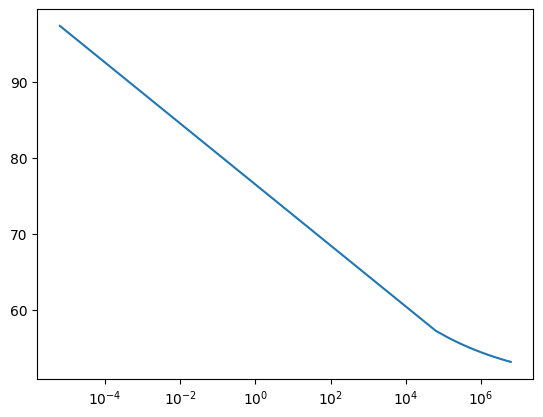

In [150]:
plt.figure()
plt.semilogx(omega, np.abs(rho_omega))